This notebooks compiles all processed datasets into a single voxel grid representation capturing the 3d distribution of cluster evidence and handles the inherent uncertainty within dataset.

Operation(s):

- Generation of support and evidence matrices for normalized convolution
- Normalized gaussian convolution of path propbabilites to get P(leaf cluster), in this case L5
- Summation of L5 descendants to derive lower granularity probailities (i.e L1-L4)

Output(s):

1. DATADIR/7_spatial/sp_voxels.zarr
    - /counts
    - /evidence
    - /L*_mass
    - /L*_prob
    - /L*_rel_mass
    - /latent_embeddings

Requirement(s):

1. DATADIR/7_spatial/SP_concat.h5ad
2. DATADIR/7_spatial/sp_voxels.zarr

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import warnings

from pathlib import Path

import pandas as pd
import scanpy as sc
import numpy as np
import zarr

from dotenv import dotenv_values
from matplotlib import pyplot as plt
from scipy.ndimage import gaussian_filter
from tqdm import tqdm

warnings.simplefilter(action='ignore', category=FutureWarning)
sc.set_figure_params(frameon=False, dpi=120, figsize=(5, 5))

In [3]:
# Setting up filepaths from config
CONFIG = dotenv_values("config.env") 
DATADIR = Path(CONFIG['DATADIR'])

OUTDIR = DATADIR / "7_spatial"

# Notebook constants
ROOT_REGION_ID = 997

SIGMA = 2
MIN_SUPPORT = 0.15

### Load objects

In [4]:
# Load voxel grid Zarr store
voxel_store = zarr.open(OUTDIR / 'sp_voxels.zarr')
voxel_store.tree()

/
├── L1_mass (6, 168, 144, 107) float32
├── L1_prob (6, 168, 144, 107) float32
├── L1_rel_mass (6, 168, 144, 107) float32
├── L2_mass (82, 168, 144, 107) float32
├── L2_prob (82, 168, 144, 107) float32
├── L2_rel_mass (82, 168, 144, 107) float32
├── L3_mass (274, 168, 144, 107) float32
├── L3_prob (274, 168, 144, 107) float32
├── L3_rel_mass (274, 168, 144, 107) float32
├── L4_mass (716, 168, 144, 107) float32
├── L4_prob (716, 168, 144, 107) float32
├── L4_rel_mass (716, 168, 144, 107) float32
├── L5_mass (932, 168, 144, 107) float32
├── L5_prob (932, 168, 144, 107) float32
├── L5_rel_mass (932, 168, 144, 107) float32
├── counts (168, 144, 107) float32
├── evidence (168, 144, 107) float32
├── latent_embedding (45, 168, 144, 107) float32
├── region_labels (168, 144, 107) uint32
└── region_masks (176, 168, 144, 107) bool

In [5]:
# Extract root mask and derive voxel shape from it
idx = voxel_store['region_masks'].attrs['ids'].index(ROOT_REGION_ID) # root region (all region encompassing)
root_mask = voxel_store['region_masks'][idx, ...]

nx, ny, nz = root_mask.shape
n_voxels = nx * ny * nz

print((nx, ny, nz), n_voxels)

(168, 144, 107) 2588544


In [6]:
# Load concatenated spatial datasets
adata = sc.read_h5ad(OUTDIR / 'SP_concat.h5ad')
adata

AnnData object with n_obs × n_vars = 1401313 × 56939
    obs: 'Dataset', 'Sample', 'Author', 'Technology', 'Donor', 'Sex', 'RegionID', 'RegionAcronym', 'RegionName', 'total_counts', 'total_hvg_counts', 'total_genes', 'IsHY'
    var: 'gene_stable_ids', 'IsHVG'
    uns: 'pathmat'
    obsm: 'P_path', 'X_embed', 'X_umap', 'X_umap_sc', 'coords_ccf_mm', 'coords_ccf_mm_wrap', 'coords_source', 'coords_voxels_25um', 'coords_voxels_25um_bounded'
    varm: 'IsCaptured'

### Sample-wise voxel aggregation

Full grid size in gigabytes can be computed by `nc * nx * ny * nz * 4 / 1024**3`. In our case: 7 gb.

In [7]:
nc = adata.obsm['P_path'].shape[1]

# Intialize empty total grids
# total_mass = csr_matrix((n_paths, n_voxels), dtype=np.float32)
total_mass = np.zeros((nc, n_voxels), dtype=np.float32)
total_counts = np.zeros(n_voxels, dtype=np.int32)
total_coverage = np.zeros(n_voxels, dtype=np.int32)
total_embed = np.zeros((45, n_voxels), dtype=np.float32) # embedding are dense

unique_sample = adata.obs['Sample'].dropna().unique()
for sample in tqdm(unique_sample):
    
    sample_indices = np.where(adata.obs['Sample'] == sample)[0]
    n_points = len(sample_indices)
    
    # Subset and extract only voxel coords for that sample
    subset = adata[sample_indices]
    coords = subset.obsm['coords_voxels_25um_bounded'].values
    ravel_coords = np.ravel_multi_index(coords.T, dims=(nx, ny, nz))
    
    # Construct counts grid
    sample_counts = np.bincount(
        ravel_coords,
        minlength=n_voxels
    ).astype(np.int32)
    
    # Infer coverage grid from counts grid
    sample_coverage = (sample_counts > 0).astype(np.int32)
    
    # Add intermediate grid to totals
    total_counts += sample_counts
    total_coverage += sample_coverage

    # Add probabilties to grid
    P = subset.obsm["P_path"].tocoo(copy=False)
    np.add.at(
        total_mass,
        (P.col, ravel_coords[P.row]),
        P.data,
    )
    
    # Add embedding direct to total
    embed = np.asarray(subset.obsm["X_embed"])
    np.add.at(total_embed.T, ravel_coords, embed)

100%|████████████████████████████████████████████████████████| 158/158 [01:58<00:00,  1.33it/s]


### Setting up support matrix

This gets confusing - there are to grids:

1. Support this is the actual normalization matrix
2. Evidence this provides a reference of how well sampled a voxel was accounting for OOB regions

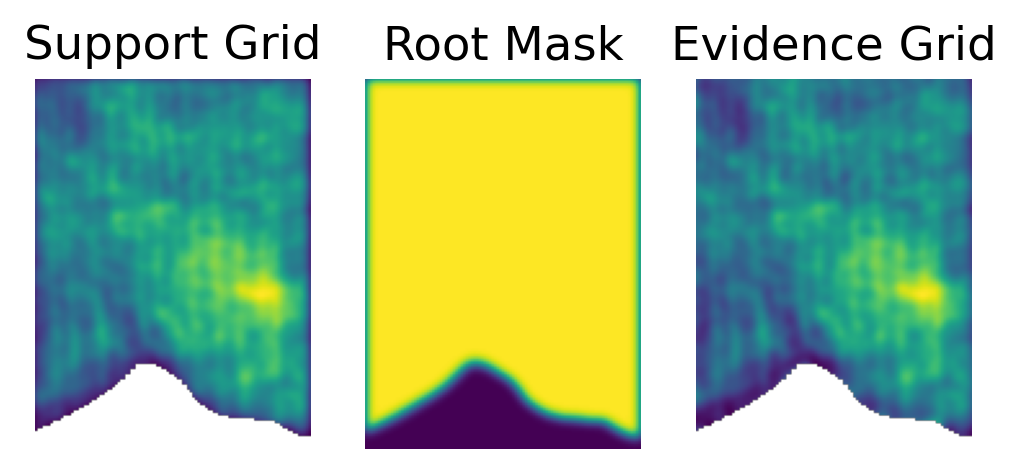

In [8]:
sampled_mask = (total_coverage > 0).astype(np.float32) # binary matrix 1 - point was sampled in this voxel 0 - missing
sampled_mask = sampled_mask.reshape(nx, ny, nz)

smoothed_support = gaussian_filter(sampled_mask, sigma=SIGMA, mode='constant', cval=0)
smoothed_root_mask = gaussian_filter(root_mask.astype(np.float32), sigma=SIGMA, mode='constant', cval=0)

# Set OOB to nan to propagate to all further grids
smoothed_support[~root_mask] = np.nan

# Normalized convolution - we don't care for voxels out of bound (not in brain/root)
smoothed_evidence = smoothed_support / (smoothed_root_mask + 1e-8)

# Save to zarr voxel store
voxel_store.create_array('evidence', shape=(nx, ny, nz), dtype=np.float32, overwrite=True, chunks=(nx, ny, nz))
voxel_store['evidence'] = smoothed_evidence

fig, axes = plt.subplots(1, 3)
axes[0].imshow(smoothed_support[100])
axes[0].axis('off')
axes[0].set_title('Support Grid')
axes[1].imshow(smoothed_root_mask[100])
axes[1].axis('off')
axes[1].set_title('Root Mask')
axes[2].imshow(smoothed_evidence[100])
axes[2].axis('off')
axes[2].set_title('Evidence Grid')
plt.show();

### Smoothing grids

In [ ]:
# normalization_factors
inv_total_coverage = total_coverage.astype(np.float32, copy=True)
inv_total_coverage[inv_total_coverage > 0] = 1 / inv_total_coverage[inv_total_coverage > 0]

In [ ]:
# ---------------------------------- Counts ---------------------------------- #

# Compute average counts per voxel across all samples
avg_counts = total_counts * inv_total_coverage
avg_counts = avg_counts.reshape(nx, ny, nz)

# Smooth counts
smoothed_avg_counts = gaussian_filter(avg_counts, sigma=SIGMA, mode='constant', cval=0)

# Normalize convolution by support grid
smoothed_avg_counts /= smoothed_support

# Save to zarr voxel store
voxel_store.create_array('counts', shape=(nx, ny, nz), dtype=np.float32, overwrite=True, chunks=(nx, ny, nz))
voxel_store['counts'] = smoothed_avg_counts.astype(np.float32)

In [11]:
# --------------------------------- Embedding -------------------------------- #

# Compute average embedding per voxel across all samples
avg_embed = total_embed * inv_total_coverage
avg_embed = avg_embed.reshape(45, nx, ny, nz)

n_features = total_embed.shape[0]

# Smooth embeddings
smoothed_avg_embed = gaussian_filter(avg_embed, sigma=SIGMA, mode='constant', cval=0, axes=(1, 2, 3))

# Normalize convolution by support grid
smoothed_avg_embed /= smoothed_support

# Save to zarr voxel store
voxel_store.create_array('latent_embedding', shape=(n_features, nx, ny, nz), dtype=np.float32, overwrite=True, chunks=(1, nx, ny, nz))
voxel_store['latent_embedding'] = smoothed_avg_embed

In [12]:
# ----------------------------------- Mass ----------------------------------- #
# All operations are in-place to avoid copies in memory :)

# Compute average mass
avg_mass = total_mass
np.multiply(avg_mass, inv_total_coverage, out=avg_mass)
avg_mass = avg_mass.reshape(nc, nx, ny, nz)

# Smoothing along x, y and z dimensions
smoothed_avg_mass = avg_mass
gaussian_filter(
    smoothed_avg_mass,
    sigma=SIGMA,
    mode="constant",
    cval=0,
    axes=(1, 2, 3),
    output=smoothed_avg_mass,
)

# Normalize convolution by support
smoothed_avg_mass /= smoothed_support[None, :, :, :]

In [13]:
# ------------------------------- Probabilities ------------------------------ #

# Probabilities theoretically can be derived by mass / counts
smoothed_probs = smoothed_avg_mass / smoothed_avg_counts[None, ...].astype(np.float32)

# Renormalize by voxelsums for true probabilities
voxel_sum = np.sum(smoothed_probs, axis=0)
smoothed_probs /= voxel_sum[None, :, :, :]

In [14]:
# --------------------- Propagating Upwards to L1, L2 etc -------------------- #

pathmat = adata.uns['pathmat']

for i, level in enumerate(pathmat.T):
    
    if i == (pathmat.shape[1] - 1):
        labels = level
        n_features = len(labels)
        
        P = smoothed_probs
        M = smoothed_avg_mass
    
    else:
        labels, inv = np.unique(level, return_inverse=True)
        n_features = len(labels)
        
        A = inv[:, None] == np.arange(len(labels))
        
        P = np.tensordot(A.T, smoothed_probs, axes=(1, 0))
        M = np.tensordot(A.T, smoothed_avg_mass, axes=(1, 0))
    
    key = f"L{i+1}"

    # Get relative mass safely
    mass_sum = np.nansum(M, axis=(1, 2, 3), keepdims=True)  # (n_features, 1, 1, 1)
    RM = np.where(
        mass_sum > 0,
        M / np.where(mass_sum > 0, mass_sum, 1.0),
        0.0
    ).astype(np.float32)

    # Initialise arrays in Zarr voxel store
    voxel_store.create_array(f'{key}_prob', shape=(n_features, nx, ny, nz), dtype=np.float32, overwrite=True, chunks=(1, nx, ny, nz))
    voxel_store.create_array(f'{key}_mass', shape=(n_features, nx, ny, nz), dtype=np.float32, overwrite=True, chunks=(1, nx, ny, nz))
    voxel_store.create_array(f'{key}_rel_mass', shape=(n_features, nx, ny, nz), dtype=np.float32, overwrite=True, chunks=(1, nx, ny, nz))
    
    # Write to Zarr arrays
    voxel_store[f'{key}_prob'] = P
    voxel_store[f"{key}_mass"] = M
    voxel_store[f"{key}_rel_mass"] = RM
    
    # Write metadata
    labels = labels.tolist()    
    ids = [x.split()[0] for x in labels]
    
    for arr_key in [f'{key}_prob', f'{key}_mass', f'{key}_rel_mass']:
        voxel_store[arr_key].attrs['labels'] = labels
        voxel_store[arr_key].attrs['ids'] = ids